# Identification des paramètres thermiques par fusion CNN-GRU + MLP

## Objectif de l'expérience

Cette expérience étudie une **architecture hybride combinant un CNN-GRU et un perceptron multicouche (MLP)** pour estimer les propriétés thermiques d'un bâtiment à partir de deux représentations complémentaires :

- **CNN-GRU :** extraction des caractéristiques temporelles à partir des signaux de température $T(t)$ et de sollicitation $U(t)$.
- **MLP :** exploitation des caractéristiques statistiques extraites de ces mêmes signaux.

Les représentations apprises sont concaténées avant la prédiction des indicateurs thermiques.

Cette expérience conserve l'architecture de fusion précédente (50/50), mais modifie la **pondération de la fonction de perte** : 30 % pour les coefficients de déperdition thermique et 70 % pour les constantes de temps.

L'objectif est d'évaluer si une importance accrue accordée aux constantes de temps améliore leur estimation, sans dégrader significativement celle des coefficients de déperdition.

## 1. Environnement d'exécution

Les fonctions de chargement des données, de définition des architectures, de calcul de la fonction de perte, d'entraînement et d'évaluation sont regroupées dans `src/coenergy/`.

Cette organisation modulaire permet de réutiliser les mêmes composants entre les expériences et de faciliter la reproductibilité des résultats.

In [2]:
from pathlib import Path
from zipfile import ZipFile
import shutil
import sys

import torch
from IPython.display import display, FileLink


def find_source_directory():
    """Localise les modules Python du projet coEnergy."""

    current_directory = Path.cwd().resolve()

    for directory in (current_directory, *current_directory.parents):
        source_directory = directory / "src"
        if (source_directory / "coenergy" / "loss.py").is_file():
            return source_directory

    kaggle_directory = Path("/kaggle/input")

    if kaggle_directory.is_dir():
        module_files = list(kaggle_directory.rglob("src/coenergy/loss.py"))
        if module_files:
            return module_files[0].parent.parent

        archives = list(kaggle_directory.rglob("coenergy_modules_kaggle.zip"))
        if archives:
            destination = Path("/kaggle/working/coenergy_code")

            with ZipFile(archives[0]) as archive:
                archive.extractall(destination)

            source_directory = destination / "src"
            if (source_directory / "coenergy" / "loss.py").is_file():
                return source_directory

    raise FileNotFoundError(
        "Modules coEnergy introuvables : ajouter le dataset contenant "
        "coenergy_modules_kaggle.zip."
    )


source_directory = find_source_directory()
sys.path.insert(0, str(source_directory))

from coenergy.data import load_data, BatchStore
from coenergy.models import build_model
from coenergy.loss import reconstruct_six, family_loss
from coenergy.training import default_config, seed_everything, Experiment
from coenergy.evaluation import evaluate_all, extreme_diagnostics
from coenergy.plotting import plot_training, plot_scores, plot_scatter

print("Modules coEnergy chargés depuis :", source_directory)

Modules coEnergy chargés depuis : /kaggle/input/datasets/bilalaouiss/dataset/coenergy_modules_kaggle/src


## 2. Configuration expérimentale

La configuration `fusion_30_70`, définie dans `training.py`, fixe le protocole suivant :

- **120 époques au maximum** et **mini-batchs de 1 024 simulations** ;
- optimisation par **AdamW**, avec adaptation du taux d'apprentissage selon la validation ;
- **arrêt anticipé** après 18 époques sans amélioration suffisante ;
- pondération **0,30 / 0,70** des deux familles de cibles.

Une graine aléatoire fixe facilite la reproductibilité. Le dossier `RUN_ID` distingue les expériences ; une reprise nécessite les checkpoints et la configuration du même entraînement.

In [3]:
MODEL_KIND = "fusion_30_70"
RUN_ID = "run_001"
DATA_ROOT = None
RUN_TRAINING = True
RESUME = True

config = default_config(MODEL_KIND, RUN_ID)
seed_everything(config.seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if Path("/kaggle/working").is_dir():
    results_directory = Path("/kaggle/working/results")
else:
    results_directory = source_directory.parent / "results"

output_directory = results_directory / MODEL_KIND / RUN_ID

print("Modèle :", MODEL_KIND)
print("Appareil :", device)
print("Époques maximales :", config.max_epochs)
print("Taille des mini-batchs :", config.batch_size)
print("Patience de l'arrêt anticipé :", config.early_patience)
print("Résultats :", output_directory)

Modèle : fusion_30_70
Appareil : cuda
Époques maximales : 120
Taille des mini-batchs : 1024
Patience de l'arrêt anticipé : 18
Résultats : /kaggle/working/results/fusion_30_70/run_001


## 3. Données préparées et partitions

Le jeu de données comprend **1 000 000 de simulations**, réparties selon les partitions fixées lors de l'analyse exploratoire :

| Partition | Simulations | Utilisation |
|---|---:|---|
| Entraînement | 719 885 | Ajustement des paramètres du réseau |
| Validation | 89 985 | Adaptation du taux d'apprentissage et sélection des poids |
| Test principal | 89 987 | Évaluation sur des simulations non vues |
| Réserve U | 100 143 | Évaluation sur des profils de sollicitation $U$ réservés |


In [4]:
data = load_data(DATA_ROOT, expected_n=1_000_000)

for partition_name, indices in data.splits.items():
    print(f"{partition_name:12s} : {len(indices):,} simulations")

print("Séries temporelles :", data.sequences.shape)
print("Caractéristiques statistiques :", data.features.shape)
print("Cibles thermiques :", data.targets.shape)
print("Caractéristiques retenues :", data.n_features)

Données préparées : 1,000,000 simulations
Caractéristiques MLP : 58
train        : 719,885 simulations
validation   : 89,985 simulations
test         : 89,987 simulations
reserve_u    : 100,143 simulations
Séries temporelles : (1000000, 2, 480)
Caractéristiques statistiques : (1000000, 59)
Cibles thermiques : (1000000, 6)
Caractéristiques retenues : 58


## 4. Préparation des entrées

Chaque simulation possède **deux types de représentation**.

**Entrée temporelle :** les séries $T$ et $U$, comprenant chacune 480 observations. Pour un mini-batch de taille $B$, l'entrée de la branche CNN-GRU est de dimension $(B,2,480)$.

Les normalisations sont celles calculées exclusivement sur le train :

$$
\widetilde T=\frac{T-\mu_{T,\mathrm{train}}}{\sigma_{T,\mathrm{train}}},
\qquad
\widetilde U=\frac{U}{\mathrm{RMS}_{U,\mathrm{train}}}.
$$

**Entrée statistique :** 59 caractéristiques extraites lors du prétraitement, dont **58 retenues** après exclusion d'une caractéristique constante sur le train. Elles sont standardisées à l'aide des statistiques de cette partition.

`BatchStore` applique ces transformations et fournit les séries temporelles, les caractéristiques et les six cibles de chaque mini-batch.

In [5]:
training_data = BatchStore(
    bundle=data,
    mode="fusion",
    device=device,
)

sample_signals, sample_features, sample_targets = training_data.get_batch(
    data.splits["train"][:8]
)

print("Séries temporelles :", tuple(sample_signals.shape))
print("Caractéristiques statistiques :", tuple(sample_features.shape))
print("Cibles thermiques :", tuple(sample_targets.shape))

Données fusion en mémoire : cuda
Séries temporelles : (8, 2, 480)
Caractéristiques statistiques : (8, 58)
Cibles thermiques : (8, 6)


## 5. Architecture de fusion CNN-GRU + MLP

Le modèle combine deux encodeurs entraînés conjointement.

| Composante | Architecture | Sortie |
|---|---|---:|
| CNN-GRU | Convolutions 1D à 16, 32 et 48 canaux, suivies d'un GRU à 64 unités et d'une projection | 64 valeurs |
| MLP | Couches entièrement connectées $58\to64\to32$ | 32 valeurs |
| Fusion | Concaténation des représentations, puis régression $96\to96\to5$ | 5 valeurs |

La branche CNN-GRU associe le dernier état caché du GRU à la moyenne des états temporels. Sa projection produit 64 valeurs, concaténées aux 32 valeurs issues du MLP, soit une représentation commune de 96 valeurs.

Le réseau prédit les cinq paramètres indépendants $HLC_{ext}$, $HLC_{mit}$, $\tau_b$, $\tau_n$ et $\tau_\infty$. L'activation **Softplus** impose des sorties positives. Le coefficient total est ensuite reconstruit par la relation :

$$
\widehat{HLC}=\widehat{HLC}_{ext}+\widehat{HLC}_{mit}.
$$

Les couches et les dimensions sont définies dans `models.py`. La pondération 30/70 ne modifie **aucune couche** de ce modèle.

In [6]:
model = build_model(MODEL_KIND, data.prep).to(device)

number_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

model.eval()

with torch.no_grad():
    five_predictions = model(sample_signals, sample_features)
    six_predictions = reconstruct_six(five_predictions)

print(model)
print("Paramètres entraînables :", f"{number_parameters:,}")
print("Prédictions indépendantes :", tuple(five_predictions.shape))
print("Indicateurs reconstruits :", tuple(six_predictions.shape))

ThermalFusion(
  (temporal): TemporalEncoder(
    (cnn): Sequential(
      (0): Conv1d(2, 16, kernel_size=(7,), stride=(2,), padding=(3,))
      (1): SiLU()
      (2): Conv1d(16, 32, kernel_size=(5,), stride=(2,), padding=(2,))
      (3): SiLU()
      (4): Conv1d(32, 48, kernel_size=(5,), stride=(2,), padding=(2,))
      (5): SiLU()
    )
    (gru): GRU(48, 64, batch_first=True)
    (projection): Sequential(
      (0): Linear(in_features=128, out_features=64, bias=True)
      (1): SiLU()
      (2): Dropout(p=0.1, inplace=False)
    )
  )
  (statistical): StatisticalEncoder(
    (network): Sequential(
      (0): Linear(in_features=58, out_features=64, bias=True)
      (1): SiLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=64, out_features=32, bias=True)
      (4): SiLU()
    )
  )
  (regressor): Sequential(
    (0): Linear(in_features=96, out_features=96, bias=True)
    (1): SiLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=96, out_fea

## 6. Fonction de perte pondérée 30/70

La fonction de perte porte sur les **cinq paramètres indépendants**. Les erreurs sont divisées par les écarts-types $s_j$ calculés sur le train afin de limiter les différences d'échelle entre les cibles.

Deux erreurs quadratiques moyennes sont calculées :

$$
\mathcal{L}_{HLC}=\frac{1}{2}
\sum_{j\in\{HLC_{ext},HLC_{mit}\}}
\operatorname{MSE}\!\left(\frac{\widehat y_j-y_j}{s_j}\right),
$$

$$
\mathcal{L}_{\tau}=\frac{1}{3}
\sum_{j\in\{\tau_b,\tau_n,\tau_\infty\}}
\operatorname{MSE}\!\left(\frac{\widehat y_j-y_j}{s_j}\right).
$$

La perte totale est :

$$
\boxed{\mathcal{L}=0{,}30\,\mathcal{L}_{HLC}+0{,}70\,\mathcal{L}_{\tau}}.
$$

Cette pondération accorde **davantage d'importance aux erreurs sur les constantes de temps**, qui sont difficiles à estimer. Le $HLC$ total, reconstruit à partir de ses composantes, n'est pas pénalisé séparément.

L'expérience 50/50 et celle-ci permettent de comparer l'effet de la pondération à **architecture et données identiques** ; une amélioration devra être constatée sur les métriques, et non supposée.

In [7]:
initial_loss = family_loss(
    five_predictions.float(),
    sample_targets,
    data.prep["target_std"],
    hlc_weight=config.hlc_weight,
    tau_weight=config.tau_weight,
)

print("Perte initiale :", round(initial_loss.item(), 6))
print("Poids de la famille HLC :", config.hlc_weight)
print("Poids de la famille des constantes de temps :", config.tau_weight)

Perte initiale : 1.102976
Poids de la famille HLC : 0.3
Poids de la famille des constantes de temps : 0.7


## 7. Entraînement et validation

Les deux branches et la tête de régression sont **optimisées conjointement** sur la partition d'entraînement. La validation sert à adapter le taux d'apprentissage et à retenir les meilleurs poids, sans utiliser les données de test.

L'optimisation utilise AdamW, une limitation de la norme du gradient et la précision mixte sur GPU. L'arrêt anticipé intervient lorsque la validation ne progresse plus suffisamment.

Le fichier `best.pt` contient les meilleurs poids selon la validation. `last.pt` conserve l'état permettant une reprise, tandis que `history.csv` décrit les pertes et le taux d'apprentissage au fil des époques.

Lorsque `RUN_TRAINING = False`, les checkpoints et l'historique doivent déjà être présents dans le dossier de l'expérience.

In [8]:
experiment = Experiment(
    config=config,
    bundle=data,
    store=training_data,
    model=model,
    out_dir=output_directory,
    device=device,
)

if RUN_TRAINING:
    history = experiment.fit(resume=RESUME)
    print("Époques enregistrées :", len(history))
else:
    print("Entraînement désactivé : utilisation des checkpoints existants.")

Mini-batch 100 | Loss train : 0.94856
Mini-batch 200 | Loss train : 0.94386
Mini-batch 300 | Loss train : 0.93954
Mini-batch 400 | Loss train : 0.93658
Mini-batch 500 | Loss train : 0.93424
Mini-batch 600 | Loss train : 0.93254
Mini-batch 700 | Loss train : 0.93173
Époque 001 | train=0.93170 | validation=0.94292 | meilleure=1 | durée=9.8s
Mini-batch 100 | Loss train : 0.92963
Mini-batch 200 | Loss train : 0.92446
Mini-batch 300 | Loss train : 0.92483
Mini-batch 400 | Loss train : 0.92329
Mini-batch 500 | Loss train : 0.92303
Mini-batch 600 | Loss train : 0.92298
Mini-batch 700 | Loss train : 0.92174
Époque 002 | train=0.92173 | validation=0.92527 | meilleure=2 | durée=8.3s
Mini-batch 100 | Loss train : 0.91867
Mini-batch 200 | Loss train : 0.91642
Mini-batch 300 | Loss train : 0.91917
Mini-batch 400 | Loss train : 0.92027
Mini-batch 500 | Loss train : 0.91731
Mini-batch 600 | Loss train : 0.91719
Mini-batch 700 | Loss train : 0.91693
Époque 003 | train=0.91699 | validation=0.91731 | me

## 8. Sélection du modèle et courbes d'apprentissage

Les évaluations sont réalisées avec le **meilleur checkpoint de validation**, et non avec les derniers poids obtenus.

Les courbes d'apprentissage permettent d'examiner la convergence, l'évolution de l'écart entre entraînement et validation et la diminution éventuelle du taux d'apprentissage.

Meilleure époque : 120


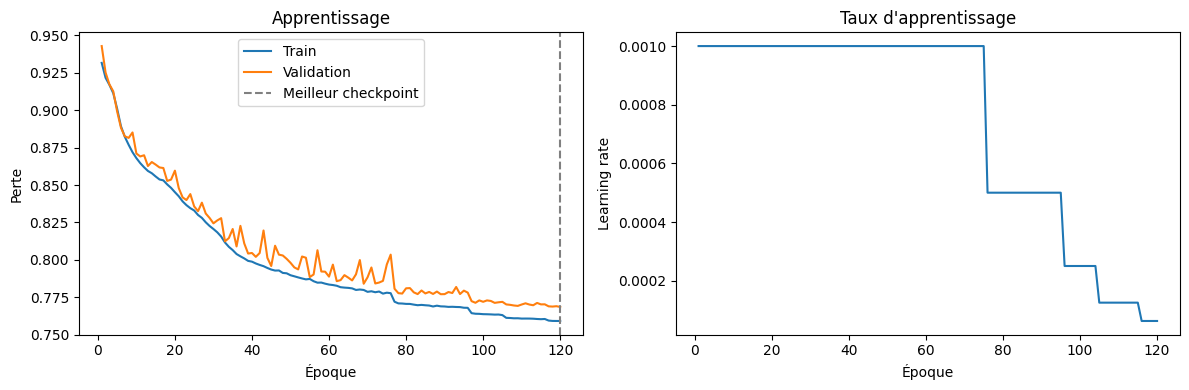

In [9]:
best_epoch = experiment.load_best()

print("Meilleure époque :", best_epoch)

plot_training(
    experiment.history_path,
    output_directory / "figures",
    best_epoch,
)

## 9. Évaluation des performances

Le meilleur modèle est évalué sur la **validation**, le **test principal** et la **réserve U**. Pour chaque paramètre physique, les métriques comprennent :

- la **MAE**, erreur absolue moyenne dans l'unité de la cible ;
- la **RMSE**, racine de l'erreur quadratique moyenne ;
- le **$R^2$**, coefficient de détermination ;
- le **biais**, moyenne des différences entre prédictions et références.

Une référence constante fondée sur les **moyennes des cibles du train** est également évaluée. Les métriques sur le test principal et la réserve U serviront à comparer la pondération 30/70 à celle de 50/50, en maintenant les mêmes partitions.

,partition,target,unit,MAE,RMSE,R2,bias
12,test,HLC,W/K,18.7595,23.5036,0.4382,-0.0361
13,test,HLCext,W/K,9.8033,12.2372,0.4871,-0.0073
14,test,HLCmit,W/K,17.9713,22.3604,0.2759,-0.0288
15,test,tau_b,h,7.3335,9.3259,0.1436,-0.1115
16,test,tau_n,h,1.3480,1.7138,0.2726,0.0036
17,test,tau_inf,h,5.5378,7.0788,0.1116,-0.0577
24,reserve_u,HLC,W/K,18.6399,23.3531,0.4454,-0.1418
25,reserve_u,HLCext,W/K,9.8235,12.2765,0.4835,-0.0532
26,reserve_u,HLCmit,W/K,17.9017,22.2821,0.2812,-0.0886
27,reserve_u,tau_b,h,7.3695,9.3894,0.1404,-0.0403


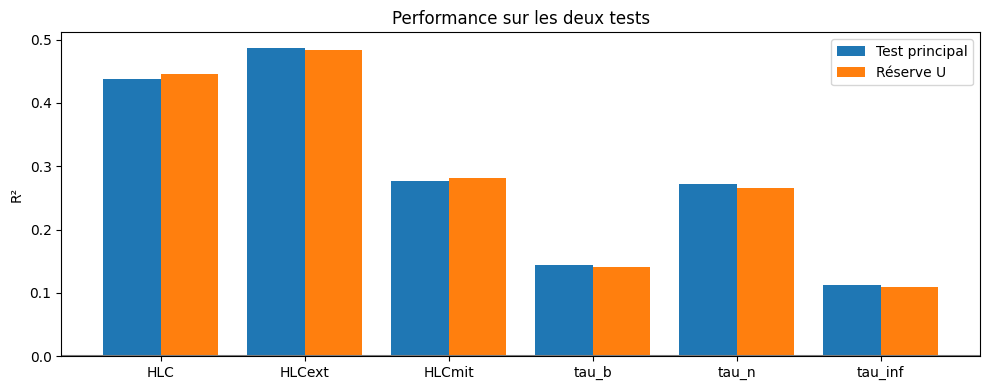

In [10]:
metrics = evaluate_all(experiment)

selected_metrics = metrics[
    (metrics["model"] == MODEL_KIND)
    & (metrics["partition"].isin(["test", "reserve_u"]))
]

display(
    selected_metrics[
        ["partition", "target", "unit", "MAE", "RMSE", "R2", "bias"]
    ].round(4)
)

plot_scores(metrics, MODEL_KIND, output_directory / "figures")

## 10. Analyse des prédictions et des valeurs extrêmes

Les diagrammes de dispersion représentent les prédictions et les valeurs réelles du test principal. La diagonale indique une prédiction parfaite et facilite l'observation des écarts systématiques.

Une analyse complémentaire porte sur les constantes de temps $\tau_b$ et $\tau_\infty$ dans les régions extrêmes. Les **5e et 95e percentiles sont calculés sur le train**, puis les erreurs sont mesurées sur le test et la réserve U.

Cette analyse est particulièrement pertinente pour examiner l'effet de la pondération accrue accordée à la famille des constantes de temps.

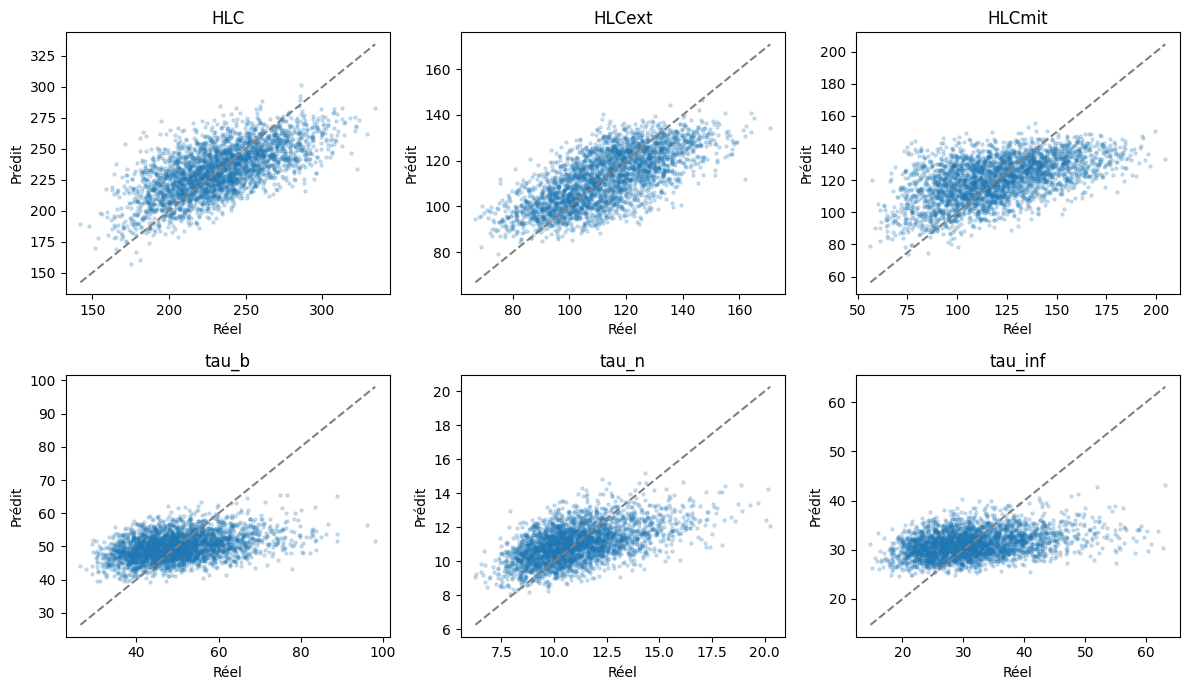

,partition,target,region,n,RMSE,bias
0,test,tau_b,5 % faibles,4447,14.030200,13.600300
1,test,tau_b,5 % élevés,4446,22.803301,-21.787001
2,test,tau_inf,5 % faibles,4475,10.471200,10.209000
3,test,tau_inf,5 % élevés,4399,17.929300,-17.136801
4,reserve_u,tau_b,5 % faibles,5055,14.248600,13.805800
5,reserve_u,tau_b,5 % élevés,5095,22.817499,-21.795300
6,reserve_u,tau_inf,5 % faibles,4987,10.612500,10.343500
7,reserve_u,tau_inf,5 % élevés,5094,17.914101,-17.129499


In [11]:
plot_scatter(
    output_directory / "predictions" / "test.npz",
    output_directory / "figures",
    seed=config.seed,
)

extreme_metrics = extreme_diagnostics(experiment)
display(extreme_metrics.round(4))

## 11. Sauvegarde des résultats

Les modèles entraînés, les configurations, les historiques d'entraînement, les métriques d'évaluation, les prédictions et les figures sont enregistrés afin d'assurer la traçabilité et la reproductibilité des expériences.

L'ensemble des résultats est également regroupé dans une archive ZIP.

In [12]:
results_dir = Path("/kaggle/working/results/fusion_30_70/run_001")

if not (results_dir / "metrics.csv").exists():
    raise FileNotFoundError("Évaluation non terminée : metrics.csv absent.")

archive = shutil.make_archive(
    "/kaggle/working/fusion_30_70_coenergy",
    "zip",
    root_dir=results_dir
)

file = Path(archive)

print("Fichier prêt :", file.exists())
print("Taille :", round(file.stat().st_size / 1024**2, 2), "Mo")
print("Nom :", file.name)

Fichier prêt : True
Taille : 12.39 Mo
Nom : fusion_30_70_coenergy.zip



## 12. Analyse et interprétation des résultats

Cette expérience reprend l'architecture de fusion CNN-GRU + MLP en modifiant uniquement la pondération de la fonction de perte. La contribution des constantes de temps est augmentée de 50 % à 70 %, tandis que celle des coefficients de déperdition est réduite à 30 %.

L'objectif était d'accorder davantage d'importance aux paramètres τb, τn et τ∞, dont les performances restaient limitées lors des expériences précédentes.

### Performances prédictives

| Paramètre | R² — Test | R² — Réserve U |
|---|---:|---:|
| HLC | 0.437 | 0.441 |
| HLCext | 0.481 | 0.479 |
| HLCmit | 0.277 | 0.281 |
| τb | 0.140 | 0.137 |
| τn | 0.269 | 0.262 |
| τ∞ | 0.109 | 0.107 |

Contrairement à l'hypothèse initiale, l'augmentation du poids des constantes de temps n'a pas permis d'améliorer leurs performances. Pour τb, le R² passe de 0.144 avec la fusion 50/50 à 0.140 avec la fusion 30/70. Des diminutions similaires sont observées pour τn et τ∞.

Les coefficients de déperdition présentent également des performances légèrement inférieures à celles de la configuration équilibrée. L'ensemble de ces résultats indique que la pondération 30/70 n'apporte pas de bénéfice dans les conditions de cette expérience.

Plusieurs hypothèses peuvent expliquer cette observation. Une pondération plus élevée modifie les contributions relatives des gradients, sans nécessairement apporter de nouvelles informations sur les constantes de temps. Les signaux de sollicitation peuvent également ne pas permettre de distinguer suffisamment certaines configurations thermiques. Enfin, la modification des poids peut modifier le compromis d'optimisation entre les différentes sorties du réseau.

Ces explications restent des hypothèses : une étude de plusieurs pondérations et plusieurs graines aléatoires serait nécessaire pour identifier les mécanismes responsables.

### Conclusion

La pondération 30/70 n'a pas amélioré l'identification des constantes de temps et conduit à des performances légèrement inférieures à celles de la fusion 50/50. Ce résultat montre que l'augmentation du poids d'une famille de paramètres dans la fonction de perte ne garantit pas une meilleure précision prédictive.
